#### Model Training

**Import Data and Required Packages**  
- Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.
- Importing Column Transformers
- Importing Model Libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

Import the CSV dataset as Pandas DataFrame

In [3]:
df = pd.read_csv("data/stud.csv")

Show top 5 records

In [4]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Preparing X and y variables

In [7]:
X = df.drop(columns=["math_score"])
y = df["math_score"]

In [8]:
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [9]:
y.head()

0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64

In [12]:
for feature in X.columns:
    if X[feature].dtype=="str":
        print(f"Categories in `{feature}` variable: ")
        print(X[feature].unique(), end="\n\n")

Categories in `gender` variable: 
<StringArray>
['female', 'male']
Length: 2, dtype: str

Categories in `race_ethnicity` variable: 
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

Categories in `parental_level_of_education` variable: 
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

Categories in `lunch` variable: 
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

Categories in `test_preparation_course` variable: 
<StringArray>
['none', 'completed']
Length: 2, dtype: str



In [18]:
numerical_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(exclude="number").columns

print("Numerical Features: ", numerical_features)
print("Categorical Features: ", categorical_features)

Numerical Features:  Index(['reading_score', 'writing_score'], dtype='str')
Categorical Features:  Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course'],
      dtype='str')


In [19]:
numerical_transformer = StandardScaler()
ohe = OneHotEncoder()

preprocessor = ColumnTransformer([
    ("OneHotEncoder", ohe, categorical_features),
    ("StandardScaler", numerical_transformer, numerical_features)
])

In [20]:
X = preprocessor.fit_transform(X)
X.shape

(1000, 19)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(800, 19) (200, 19)


Create an Evaluation function to give all metrics after model training

In [24]:
def evaluate_model(actual_values, predicted_values):
    mae = mean_absolute_error(actual_values, predicted_values)
    mse = mean_squared_error(actual_values, predicted_values)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual_values, predicted_values)

    return mae, rmse, r2

In [28]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(), 
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}

model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print("Model performance for Training Dataset")
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print("----------------------------------")
    
    print("Model performance for Test Dataset")
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print("="*35)
    print("\n")

Linear Regression
Model performance for Training Dataset
- Root Mean Squared Error: 5.3231
- Mean Absolute Error: 4.2667
- R2 Score: 0.8743
----------------------------------
Model performance for Test Dataset
- Root Mean Squared Error: 5.3940
- Mean Absolute Error: 4.2148
- R2 Score: 0.8804


Lasso
Model performance for Training Dataset
- Root Mean Squared Error: 6.5938
- Mean Absolute Error: 5.2063
- R2 Score: 0.8071
----------------------------------
Model performance for Test Dataset
- Root Mean Squared Error: 6.5197
- Mean Absolute Error: 5.1579
- R2 Score: 0.8253


Ridge
Model performance for Training Dataset
- Root Mean Squared Error: 5.3233
- Mean Absolute Error: 4.2650
- R2 Score: 0.8743
----------------------------------
Model performance for Test Dataset
- Root Mean Squared Error: 5.3904
- Mean Absolute Error: 4.2111
- R2 Score: 0.8806


K-Neighbors Regressor
Model performance for Training Dataset
- Root Mean Squared Error: 5.7077
- Mean Absolute Error: 4.5167
- R2 Score: 0.

#### Results

In [32]:
pd.DataFrame({"Model": model_list, "R2 Score": r2_list}).sort_values(by="R2 Score", ascending=False)

,Model,R2 Score
2,Ridge,0.880593
0,Linear Regression,0.880433
5,Random Forest Regressor,0.853237
8,AdaBoost Regressor,0.852124
7,CatBoosting Regressor,0.851632
6,XGBRegressor,0.827797
1,Lasso,0.825320
3,K-Neighbors Regressor,0.783813
4,Decision Tree,0.758854


#### Linear Regression

In [41]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)

y_pred = lin_model.predict(X_test)

r2 = r2_score(y_test, y_pred)*100

print("Accuracy of the model: {:.2f}%".format(r2))

Accuracy of the model: 88.04%


**Plot `y_test` and `y_pred`**

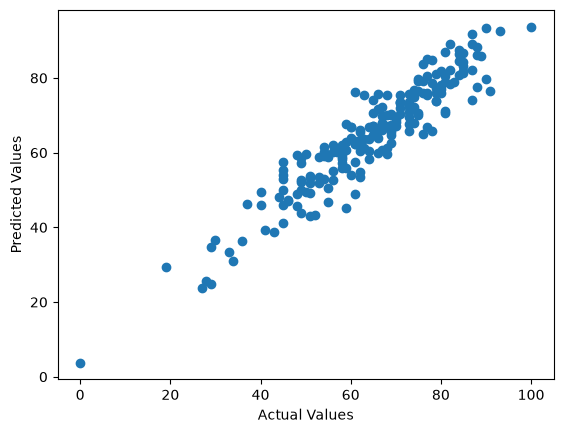

In [42]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()

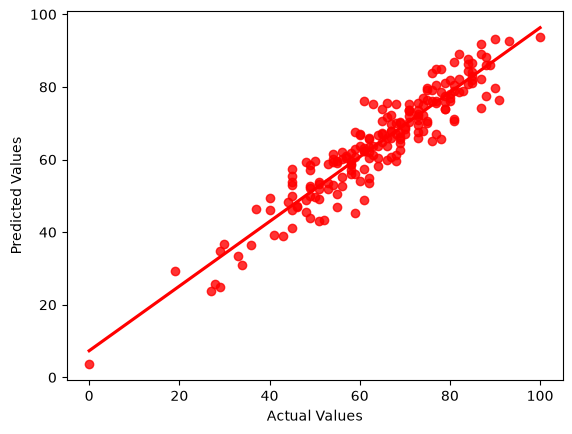

In [43]:
sns.regplot(x=y_test, y=y_pred, ci=None, color ="red")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()

**Difference between Actual and Predicted Values**

In [45]:
pred_df = pd.DataFrame({"Actual Values": y_test, "Predicted Values": y_pred, "Difference": y_test-y_pred})

pred_df

,Actual Values,Predicted Values,Difference
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
...,...,...,...
408,52,43.409149,8.590851
332,62,62.152214,-0.152214
208,74,67.888395,6.111605
613,65,67.022287,-2.022287
